# Escalado
Conjunto de datos: iris (incluido en sklearn)
Este conjunto de datos es compacto y perfecto para demostrar técnicas de escalado.

In [7]:
# PASO 1: Importamos las librerías necesarias
from sklearn.datasets import load_iris              # Carga el dataset de prueba sobre flores Iris integrado en Scikit-Learn.
from sklearn.preprocessing import MinMaxScaler, StandardScaler  # Importa los dos transformadores para escalar (MinMax = rango 0 a 1, Standard = media 0 y std 1).
import pandas as pd                                  # Librería para estructurar los datos en tablas (DataFrames).
import matplotlib.pyplot as plt                      # Librería para crear y visualizar gráficas.

In [8]:
# PASO 2: Carga y extracción de la matriz de características
iris = load_iris(as_frame=True)  # 'as_frame=True' fuerza a la librería a envolver las variables en estructuras de Pandas (Series y DataFrames) en lugar de arreglos planos.
data = iris.data                 # 'data' extrae del objeto 'iris' ÚNICAMENTE la matriz de variables numéricas independientes (las 4 mediciones físicas de las flores), dejando fuera la columna de respuestas o clases ('target').

In [9]:
# PASO 3: Diagnóstico de la matriz sin transformar
print("Estadísticas iniciales:")
print(data.describe())   # Imprime el resumen de 8 valores estadísticos (conteo, media, std, min, percentiles, max) de cada variable en su unidad original de medida (centímetros).

Estadísticas iniciales:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


In [10]:
# PASO 4: Escalado por Rango Fijo (MinMaxScaler)
minmax_scaler = MinMaxScaler()   # Crea el objeto transformador configurado para mapear el valor mínimo a 0.0 y el valor máximo a 1.0.

# 1. 'fit_transform(data)' inspecciona la tabla 'data', detecta el valor mínimo y máximo de cada columna, y aplica la fórmula de compresión (x - min) / (max - min).
# 2. El resultado de 'fit_transform' es una matriz numérica plana (ndarray de NumPy) sin nombres de variables.
# 3. 'pd.DataFrame(..., columns=data.columns)' toma ese arreglo plano sin formato y lo empaqueta en una nueva estructura de datos (DataFrame) llamada 'data_minmax', restituyendo los nombres de las columnas en centímetros.
data_minmax = pd.DataFrame(minmax_scaler.fit_transform(data), columns=data.columns)

In [11]:
# PASO 5: Estandarización por Desviación Estándar (StandardScaler / Z-Score)
standard_scaler = StandardScaler() # Crea el objeto transformador que re-centra la distribución en 0 y escala la dispersión a 1.

# 1. 'fit_transform(data)' calcula el promedio (media) y la desviación estándar de cada variable original, y resta la media a cada registro dividiéndolo entre la std: (x - u) / s.
# 2. Retorna una matriz plana de números flotantes (NumPy ndarray).
# 3. Re-empaquetamos la matriz plana en una nueva variable de tipo DataFrame llamada 'data_standard', conservando la estructura de columnas original para poder comparar.
data_standard = pd.DataFrame(standard_scaler.fit_transform(data), columns=data.columns)

# PASO 6: Imprimimos resúmenes estadísticos para verificar los cambios de escala
print("\nEstadísticas tras MinMaxScaler (Valores entre 0 y 1):")
print(data_minmax.describe())

print("\nEstadísticas tras StandardScaler (Media = 0, Std = 1):")
print(data_standard.describe())


Estadísticas tras MinMaxScaler (Valores entre 0 y 1):
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            0.428704          0.440556           0.467458   
std             0.230018          0.181611           0.299203   
min             0.000000          0.000000           0.000000   
25%             0.222222          0.333333           0.101695   
50%             0.416667          0.416667           0.567797   
75%             0.583333          0.541667           0.694915   
max             1.000000          1.000000           1.000000   

       petal width (cm)  
count        150.000000  
mean           0.458056  
std            0.317599  
min            0.000000  
25%            0.083333  
50%            0.500000  
75%            0.708333  
max            1.000000  

Estadísticas tras StandardScaler (Media = 0, Std = 1):
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
coun

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre las estadísticas originales y las del escalado MinMax?


In [12]:
# PASO 1: Generamos el resumen estadístico de la tabla original con sus valores reales en centímetros
print("--- ESTADÍSTICAS ORIGINALES ---")
print(data.describe())

# PASO 2: Generamos el resumen estadístico del DataFrame procesado con MinMaxScaler
# Permite observar cómo el mínimo absoluto cambia a 0.0 y el máximo absoluto a 1.0 en todas las columnas
print("\n--- ESTADÍSTICAS CON MINMAXSCALER ---")
print(data_minmax.describe())

--- ESTADÍSTICAS ORIGINALES ---
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  

--- ESTADÍSTICAS CON MINMAXSCALER ---
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000  

### 2. Crea una gráfica de la distribución de la variable 'sepal length (cm)' antes y después del escalado.

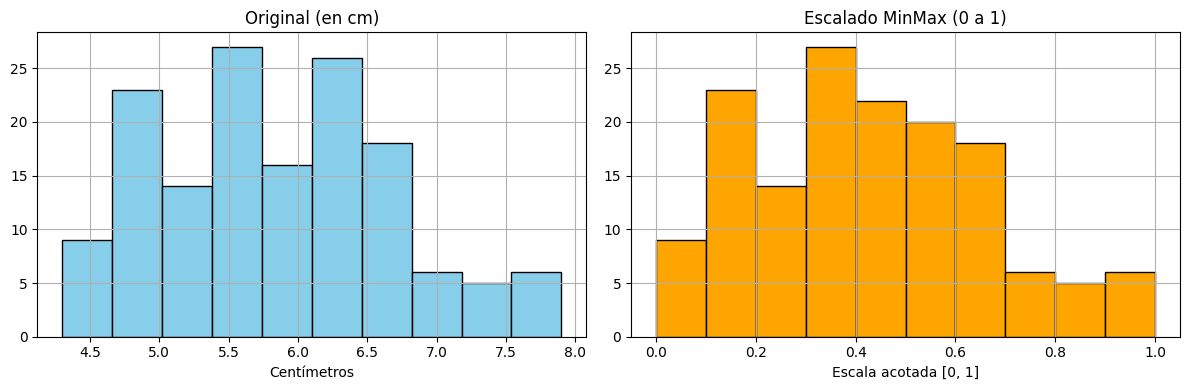

In [13]:

# Creamos lienzo con 2 subgráficas lado a lado (1 fila, 2 columnas)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfica 1: Datos originales en centímetros
data['sepal length (cm)'].hist(ax=axes[0], color='skyblue', edgecolor='black')
axes[0].set_title('Original (en cm)')
axes[0].set_xlabel('Centímetros')

# Gráfica 2: Datos escalados con MinMaxScaler (rango 0 a 1)
data_minmax['sepal length (cm)'].hist(ax=axes[1], color='orange', edgecolor='black')
axes[1].set_title('Escalado MinMax (0 a 1)')
axes[1].set_xlabel('Escala acotada [0, 1]')

plt.tight_layout()
plt.show()

### 3. Crea una gráfica de dispersión entre 'sepal length (cm)' y 'sepal width (cm)' con los datos escalados por StandardScaler.

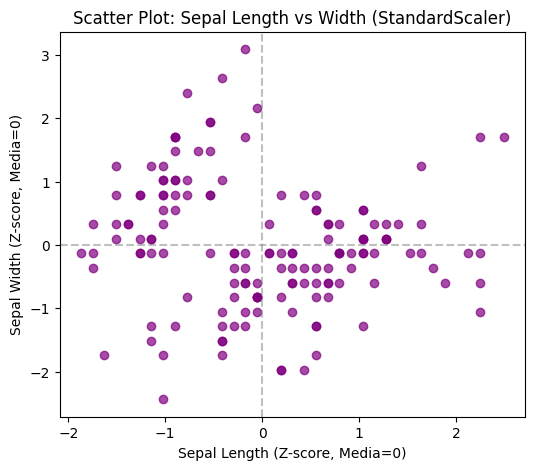

In [14]:

# Usamos el DataFrame 'data_standard' donde la media de las variables es 0 y std es 1
plt.figure(figsize=(6, 5))
plt.scatter(
    data_standard['sepal length (cm)'], 
    data_standard['sepal width (cm)'], 
    color='purple', 
    alpha=0.7
)

# Añadimos líneas de referencia en x=0 y y=0 para visualizar el centroide de la estandarización Z-score
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)

plt.title('Scatter Plot: Sepal Length vs Width (StandardScaler)')
plt.xlabel('Sepal Length (Z-score, Media=0)')
plt.ylabel('Sepal Width (Z-score, Media=0)')
plt.show()

### 4. ¿Qué técnica de escalado crees que es más adecuada para este conjunto de datos? ¿Por qué?

Para Iris me quedo con StandardScaler.

Como las mediciones de flores siguen una distribucion normal (forma de campana) y no tienen limites topados en 0 o 1, la estandarizacion mantiene la media centrada en 0 y la varianza en 1. Esto ayuda bastante a los algoritmos basados en distancia (como KNN) sin alterar la dispersion natural de los datos ni comprimirlos a la fuerza.